In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X=np.linspace(0,10,40).reshape(-1,1)
y=2 + 0.5 * X[:,0] ** 2 + np.random.normal(0,5,40)

x_train,x_test,y_train,y_test=train_test_split(
    X,y,test_size=0.30,random_state=42
)

degrees=[1,2,10]

for degree in degrees:
    model=make_pipeline(
        PolynomialFeatures(degree=degree,include_bias=False),
        LinearRegression()
    )

    model.fit(x_train,y_train)
    train_prediction=model.predict(x_train)
    test_prediction=model.predict(x_test)

    train_mse=mean_squared_error(y_train,train_prediction)
    test_mse=mean_squared_error(y_test,test_prediction)

    print(f"polynomialh degree:{degree}")
    print(f"training_degree:{train_mse:.2f}")
    print(f"testing_degree:{test_mse:.2f}")

polynomialh degree:1
training_degree:42.90
testing_degree:42.99
polynomialh degree:2
training_degree:20.44
testing_degree:19.79
polynomialh degree:10
training_degree:12.89
testing_degree:95.22


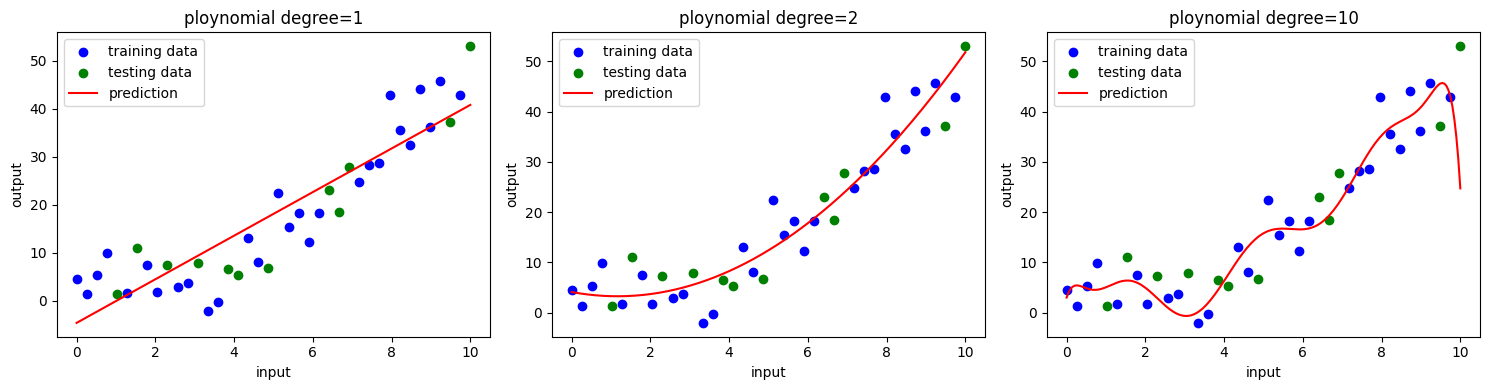

In [10]:
X_plot=np.linspace(0,10,200).reshape(-1,1)
plt.figure(figsize=(15,4))
for index,degree in enumerate(degrees):
    model=make_pipeline(
        PolynomialFeatures(degree=degree,include_bias=False),
        LinearRegression()
    )
    model.fit(x_train,y_train)
    y_plot=model.predict(X_plot)

    plt.subplot(1,3,index+1)
    plt.scatter(x_train,y_train,color="blue",label="training data")
    plt.scatter(x_test,y_test,color="green",label="testing data")
    plt.plot(X_plot,y_plot,color="red",label="prediction")

    plt.title(f"ploynomial degree={degree}")
    plt.xlabel("input")
    plt.ylabel("output")
    plt.legend()

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures



for degree in range(1, 11):
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),  
        LinearRegression()
    )
    

    scores = cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error')
  
    mse = -scores.mean()
    print(f"Degree: {degree:2d} | Mean CV MSE: {mse:.2f}")


Degree:  1 | Mean CV MSE: 110.69
Degree:  2 | Mean CV MSE: 44.22
Degree:  3 | Mean CV MSE: 71.23
Degree:  4 | Mean CV MSE: 82.46
Degree:  5 | Mean CV MSE: 1348.27
Degree:  6 | Mean CV MSE: 11392.13
Degree:  7 | Mean CV MSE: 53226.76
Degree:  8 | Mean CV MSE: 99956.80
Degree:  9 | Mean CV MSE: 1196598.08
Degree: 10 | Mean CV MSE: 11490573.91


In [22]:
import pandas as pd
from sklearn.feature_selection import VarianceThreshold

X=pd.DataFrame({
    "constant_feature":[1,1,1,1,1],
    "almost_constant":[0,0,0,0,1],
    "useful_feature":[10,20,30,40,50]
})

selector=VarianceThreshold(threshold=0.2)
X_selected=selector.fit_transform(X)
selected_columns=X.columns[selector.get_support()]
print("selected fetures:",list(selected_columns))


selected fetures: ['useful_feature']


In [24]:
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
data=pd.DataFrame({
   "study_hours":[1,2,3,4,5,6],
   "attendance":[50,55,65,70,80,90],
   "previous_marks":[35,40,50,55,65,75],
   "final_marks":[38,45,52,60,70,82]
})

                study_hours  attendance  previous_marks  final_marks
study_hours        1.000000    0.994100        0.994100     0.993478
attendance         0.994100    1.000000        1.000000     0.996852
previous_marks     0.994100    1.000000        1.000000     0.996852
final_marks        0.993478    0.996852        0.996852     1.000000


<Axes: >

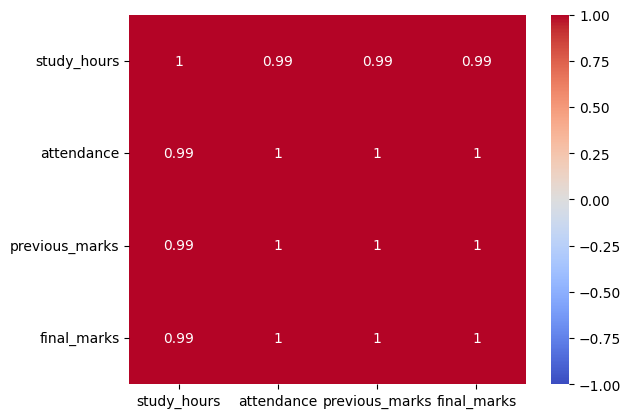

In [26]:
correlation_matrix=data.corr(numeric_only=True)
print(correlation_matrix)
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

In [29]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import MinMaxScaler


data = load_breast_cancer()
X = data.data  # Use uppercase 'X'
y = data.target


X_non_negative = MinMaxScaler().fit_transform(X)


selector = SelectKBest(score_func=chi2, k=5)
X_selected = selector.fit_transform(X_non_negative, y)


selected_features = data.feature_names[selector.get_support()]

print("Selected features:")
print(selected_features)


Selected features:
['mean concavity' 'mean concave points' 'worst perimeter' 'worst area'
 'worst concave points']


In [30]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import chi2
from sklearn.datasets import load_iris


In [31]:
iris=load_iris()
X,y=iris.data,iris.target
X.shape
X

array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
       [4.9, 3

In [33]:
X_select=SelectKBest(chi2,k=3).fit_transform(X,y)
X_select

array([[5.1, 1.4, 0.2],
       [4.9, 1.4, 0.2],
       [4.7, 1.3, 0.2],
       [4.6, 1.5, 0.2],
       [5. , 1.4, 0.2],
       [5.4, 1.7, 0.4],
       [4.6, 1.4, 0.3],
       [5. , 1.5, 0.2],
       [4.4, 1.4, 0.2],
       [4.9, 1.5, 0.1],
       [5.4, 1.5, 0.2],
       [4.8, 1.6, 0.2],
       [4.8, 1.4, 0.1],
       [4.3, 1.1, 0.1],
       [5.8, 1.2, 0.2],
       [5.7, 1.5, 0.4],
       [5.4, 1.3, 0.4],
       [5.1, 1.4, 0.3],
       [5.7, 1.7, 0.3],
       [5.1, 1.5, 0.3],
       [5.4, 1.7, 0.2],
       [5.1, 1.5, 0.4],
       [4.6, 1. , 0.2],
       [5.1, 1.7, 0.5],
       [4.8, 1.9, 0.2],
       [5. , 1.6, 0.2],
       [5. , 1.6, 0.4],
       [5.2, 1.5, 0.2],
       [5.2, 1.4, 0.2],
       [4.7, 1.6, 0.2],
       [4.8, 1.6, 0.2],
       [5.4, 1.5, 0.4],
       [5.2, 1.5, 0.1],
       [5.5, 1.4, 0.2],
       [4.9, 1.5, 0.2],
       [5. , 1.2, 0.2],
       [5.5, 1.3, 0.2],
       [4.9, 1.4, 0.1],
       [4.4, 1.3, 0.2],
       [5.1, 1.5, 0.2],
       [5. , 1.3, 0.3],
       [4.5, 1.3

In [34]:
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectKBest,f_classif
 
data=load_iris()
X=data.data
y=data.target

selector=SelectKBest(score_func=f_classif,k=2)
X_selected=selector.fit_transform(X,y)

import numpy as np 

selected_features=np.array(data.feature_names)[selector.get_support()]

print("seleccted features:",selected_features)

seleccted features: ['petal length (cm)' 'petal width (cm)']
